In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

PROJET = Path("/content/drive/MyDrive/MiniProjet-Rétinographie")
PROCESSED = PROJET / "dataset" / "processed"
MODELS = PROJET / "models"
RESULTS = PROJET / "results"

SEED = 42
TAILLE = 512
BATCH = 2
EPOCHS = 80
SEUIL = 0.5

tf.keras.utils.set_random_seed(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
with np.load(PROCESSED / "train.npz") as donnees:
    X_train = donnees["X"]
    Y_train = donnees["Y"].astype(np.float32)
    FOV_train = donnees["FOV"].astype(bool)

with np.load(PROCESSED / "validation.npz") as donnees:
    X_val = donnees["X"]
    Y_val = donnees["Y"].astype(np.float32)
    FOV_val = donnees["FOV"].astype(bool)

with np.load(PROCESSED / "test.npz") as donnees:
    X_test = donnees["X"]
    FOV_test = donnees["FOV"].astype(bool)

print("Entraînement :", X_train.shape, Y_train.shape)
print("Validation   :", X_val.shape, Y_val.shape)
print("Test         :", X_test.shape)

Entraînement : (16, 512, 512, 3) (16, 512, 512, 1)
Validation   : (4, 512, 512, 3) (4, 512, 512, 1)
Test         : (20, 512, 512, 3)


In [ ]:
CHEMIN_MODELE = MODELS / "meilleur_unet.keras"

if not CHEMIN_MODELE.is_file():
    raise FileNotFoundError(CHEMIN_MODELE)

model = tf.keras.models.load_model(
    str(CHEMIN_MODELE),
    compile=False
)

print("U-Net entraîné chargé.")
print("Entrée :", model.input_shape)
print("Sortie :", model.output_shape)

U-Net entraîné chargé.
Entrée : (None, 512, 512, 3)
Sortie : (None, 512, 512, 1)


2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step


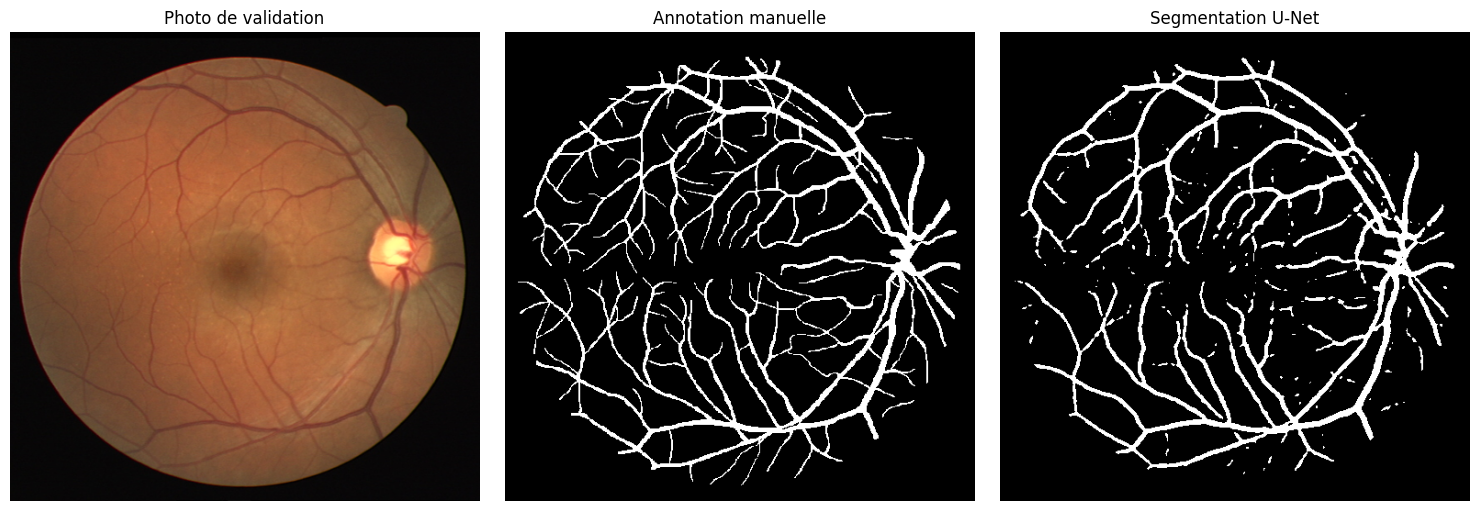

In [ ]:
probas_val = model.predict(X_val, batch_size=BATCH)

predictions_val = (
    (probas_val[..., 0] >= SEUIL)
    & FOV_val[..., 0]
)

i = 0

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(X_val[i])
axes[0].set_title("Photo de validation")

axes[1].imshow(Y_val[i, :, :, 0], cmap="gray")
axes[1].set_title("Annotation manuelle")

axes[2].imshow(predictions_val[i], cmap="gray")
axes[2].set_title("Segmentation U-Net")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step
20 photos segmentées.
Résultats sauvegardés dans : /content/drive/MyDrive/MiniProjet-Rétinographie/results/predictions_test


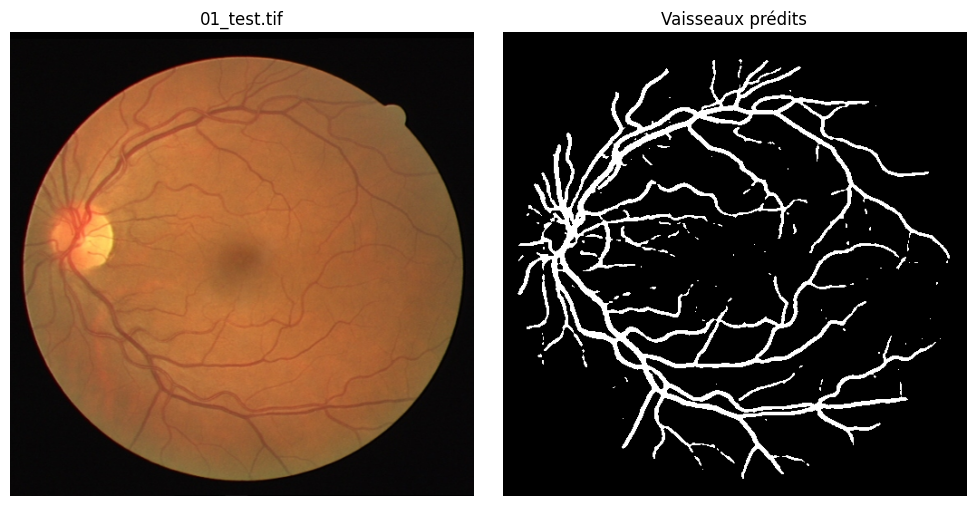

In [ ]:
import json
from PIL import Image

# Retrouver les noms des photos dans le même ordre que X_test
with open(PROCESSED / "preparation.json", encoding="utf-8") as fichier:
    preparation = json.load(fichier)

noms_test = preparation["test"]

assert len(noms_test) == len(X_test), (
    "Le nombre de noms ne correspond pas aux images chargées."
)

# Prédire puis exclure le fond extérieur à la rétine
probas_test = model.predict(X_test, batch_size=BATCH)

predictions_test = (
    (probas_test[..., 0] >= SEUIL)
    & FOV_test[..., 0]
)

destination = RESULTS / "predictions_test"
destination.mkdir(parents=True, exist_ok=True)

for nom, masque, proba in zip(
    noms_test, predictions_test, probas_test
):
    prefixe = Path(nom).stem

    Image.fromarray(
        masque.astype(np.uint8) * 255
    ).save(destination / f"{prefixe}_vaisseaux.png")

    np.save(
        destination / f"{prefixe}_probabilites.npy",
        proba[..., 0]
    )

print(f"{len(predictions_test)} photos segmentées.")
print("Résultats sauvegardés dans :", destination)

# Afficher la première prédiction
i = 0

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(X_test[i])
axes[0].set_title(noms_test[i])

axes[1].imshow(predictions_test[i], cmap="gray")
axes[1].set_title("Vaisseaux prédits")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()